# Data Cleaning and EDA

## Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from ydata_profiling import ProfileReport

C:\Users\Hemanth\AppData\Local\Temp\ipykernel_19420\2552517398.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## Load Datasets

In [4]:
customers = pd.read_csv("Downloads/global-ecommerce-orders-returns-2024-2026/customers.csv")
order_items = pd.read_csv("Downloads/global-ecommerce-orders-returns-2024-2026/order_items.csv")
orders = pd.read_csv("Downloads/global-ecommerce-orders-returns-2024-2026/orders.csv")
products = pd.read_csv("Downloads/global-ecommerce-orders-returns-2024-2026/products.csv")
returns = pd.read_csv("Downloads/global-ecommerce-orders-returns-2024-2026/returns.csv")

## Preview Datasets

In [5]:
customers.head()

,customer_id,customer_name,country,region,currency_code,signup_date,acquisition_channel,preferred_device,newsletter_opt_in,first_order_date,lifetime_orders,lifetime_spend_usd
0,CST-00001,Kofi Garcia,Saudi Arabia,Middle East,SAR,08-11-2023,Organic Search,Desktop,Yes,01-07-2024,7,3584.40
1,CST-00002,Diego Okafor,Germany,Europe,EUR,17-11-2023,Direct,Mobile,No,23-06-2024,4,1867.09
2,CST-00003,Ahmed Garcia,Germany,Europe,EUR,15-08-2023,Organic Search,Desktop,No,19-05-2024,3,1762.15
3,CST-00004,Grace Costa,United States,North America,USD,07-01-2025,Paid Search,Desktop,Yes,14-03-2026,2,669.49
4,CST-00005,Alex Patel,Japan,Asia-Pacific,JPY,12-06-2023,Organic Search,Mobile,Yes,29-01-2024,5,1136.69


In [6]:
order_items.head()

,order_item_id,order_id,product_id,quantity,unit_price_local,line_discount_local,line_total_local,line_total_usd,unit_cost_usd,line_profit_usd,currency_code
0,ITM-000001,ORD-000001,PRD-0061,1,42.78,0.00,42.78,42.78,18.99,23.79,USD
1,ITM-000002,ORD-000001,PRD-0311,1,96.79,0.00,96.79,96.79,53.60,43.19,USD
2,ITM-000003,ORD-000002,PRD-0335,1,282.11,0.00,282.11,75.23,39.08,36.15,SAR
3,ITM-000004,ORD-000003,PRD-0092,2,1122.95,369.42,1876.48,1379.76,632.31,115.14,CAD
4,ITM-000005,ORD-000003,PRD-0301,1,96.07,31.15,64.92,47.74,35.15,12.59,CAD


In [7]:
orders.head()

,order_id,customer_id,order_date,order_month,sales_channel,device_type,payment_method,shipping_country,shipping_region,currency_code,fx_rate_to_usd,items_count,gross_amount_local,discount_local,shipping_fee_local,tax_local,order_total_local,order_total_usd,order_status,delivery_days
0,ORD-008373,CST-01476,01-01-2024,2024-01,Mobile App,Mobile,Credit Card,United Arab Emirates,Middle East,AED,3.67,2,954.35,0.00,0.0,47.72,1002.07,273.04,Shipped,1.0
1,ORD-013085,CST-00125,01-01-2024,2024-01,Mobile App,Mobile,Cash on Delivery,India,Asia-Pacific,INR,83.20,4,38571.52,1722.73,0.0,6632.78,43481.57,522.62,Delivered,9.0
2,ORD-013781,CST-02849,01-01-2024,2024-01,Web Store,Desktop,Cash on Delivery,Australia,Asia-Pacific,AUD,1.52,7,2752.98,197.66,0.0,255.53,2810.85,1849.24,Delivered,5.0
3,ORD-007897,CST-00624,01-01-2024,2024-01,Web Store,Desktop,Credit Card,India,Asia-Pacific,INR,83.20,7,101415.79,5440.98,0.0,17275.47,113250.28,1361.18,Delivered,8.0
4,ORD-008525,CST-02656,01-01-2024,2024-01,Web Store,Desktop,Cash on Delivery,United Kingdom,Europe,GBP,0.79,8,814.22,43.43,0.0,154.16,924.95,1170.82,Delivered,7.0


In [8]:
products.head()

,product_id,product_name,category,subcategory,brand,list_price_usd,unit_cost_usd,weight_kg,launch_date,is_active
0,PRD-0001,Northline Footwear 0001,Apparel,Footwear,Northline,105.82,51.08,4.97,26-06-2023,Yes
1,PRD-0002,Solstice T-Shirt 0002,Apparel,T-Shirts,Marlowe,90.07,42.16,3.56,15-11-2023,Yes
2,PRD-0003,Ferrix Footwear 0003,Apparel,Footwear,Brightfold,127.19,56.37,0.44,04-11-2022,Yes
3,PRD-0004,Vantia Dresse 0004,Apparel,Dresses,Kestrel,82.41,34.30,5.59,30-11-2023,Yes
4,PRD-0005,Brightfold Footwear 0005,Apparel,Footwear,Northline,28.14,13.37,4.37,01-01-2022,Yes


In [9]:
returns.head()

,return_id,order_id,order_item_id,product_id,customer_id,return_date,return_month,days_to_return,quantity_returned,return_reason,item_condition,refund_amount_local,refund_amount_usd,restocked,currency_code
0,RET-000001,ORD-003001,ITM-006348,PRD-0016,CST-00837,30-01-2024,2024-01,28,1,Changed mind,Damaged,12720.96,152.90,No,INR
1,RET-000002,ORD-013740,ITM-029103,PRD-0049,CST-01069,11-01-2024,2024-01,9,1,Not as described,Damaged,592.48,161.44,Yes,AED
2,RET-000003,ORD-013740,ITM-029104,PRD-0158,CST-01069,10-01-2024,2024-01,8,1,Changed mind,Damaged,122.89,33.49,Yes,AED
3,RET-000004,ORD-005198,ITM-010985,PRD-0011,CST-00443,17-01-2024,2024-01,13,1,Wrong size or fit,Damaged,13157.86,158.15,Yes,INR
4,RET-000005,ORD-009829,ITM-020765,PRD-0208,CST-00528,31-01-2024,2024-01,24,1,Changed mind,Resellable,228.00,228.00,No,USD


## Dataset Information

In [10]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          3000 non-null   object 
 1   customer_name        3000 non-null   object 
 2   country              3000 non-null   object 
 3   region               3000 non-null   object 
 4   currency_code        3000 non-null   object 
 5   signup_date          3000 non-null   object 
 6   acquisition_channel  3000 non-null   object 
 7   preferred_device     3000 non-null   object 
 8   newsletter_opt_in    3000 non-null   object 
 9   first_order_date     2966 non-null   object 
 10  lifetime_orders      3000 non-null   int64  
 11  lifetime_spend_usd   3000 non-null   float64
dtypes: float64(1), int64(1), object(10)
memory usage: 281.4+ KB


In [11]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14000 entries, 0 to 13999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            14000 non-null  object 
 1   customer_id         14000 non-null  object 
 2   order_date          14000 non-null  object 
 3   order_month         14000 non-null  object 
 4   sales_channel       14000 non-null  object 
 5   device_type         14000 non-null  object 
 6   payment_method      14000 non-null  object 
 7   shipping_country    14000 non-null  object 
 8   shipping_region     14000 non-null  object 
 9   currency_code       14000 non-null  object 
 10  fx_rate_to_usd      14000 non-null  float64
 11  items_count         14000 non-null  int64  
 12  gross_amount_local  14000 non-null  float64
 13  discount_local      14000 non-null  float64
 14  shipping_fee_local  14000 non-null  float64
 15  tax_local           14000 non-null  float64
 16  orde

In [12]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29671 entries, 0 to 29670
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_item_id        29671 non-null  object 
 1   order_id             29671 non-null  object 
 2   product_id           29671 non-null  object 
 3   quantity             29671 non-null  int64  
 4   unit_price_local     29671 non-null  float64
 5   line_discount_local  29671 non-null  float64
 6   line_total_local     29671 non-null  float64
 7   line_total_usd       29671 non-null  float64
 8   unit_cost_usd        29671 non-null  float64
 9   line_profit_usd      29671 non-null  float64
 10  currency_code        29671 non-null  object 
dtypes: float64(6), int64(1), object(4)
memory usage: 2.5+ MB


In [13]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 345 entries, 0 to 344
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      345 non-null    object 
 1   product_name    345 non-null    object 
 2   category        345 non-null    object 
 3   subcategory     345 non-null    object 
 4   brand           345 non-null    object 
 5   list_price_usd  345 non-null    float64
 6   unit_cost_usd   345 non-null    float64
 7   weight_kg       345 non-null    float64
 8   launch_date     345 non-null    object 
 9   is_active       345 non-null    object 
dtypes: float64(3), object(7)
memory usage: 27.1+ KB


In [14]:
returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2433 entries, 0 to 2432
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   return_id            2433 non-null   object 
 1   order_id             2433 non-null   object 
 2   order_item_id        2433 non-null   object 
 3   product_id           2433 non-null   object 
 4   customer_id          2433 non-null   object 
 5   return_date          2433 non-null   object 
 6   return_month         2433 non-null   object 
 7   days_to_return       2433 non-null   int64  
 8   quantity_returned    2433 non-null   int64  
 9   return_reason        2433 non-null   object 
 10  item_condition       2433 non-null   object 
 11  refund_amount_local  2433 non-null   float64
 12  refund_amount_usd    2433 non-null   float64
 13  restocked            2433 non-null   object 
 14  currency_code        2433 non-null   object 
dtypes: float64(2), int64(2), object(11)
me

## Dataset Description

In [15]:
customers.describe()

,lifetime_orders,lifetime_spend_usd
count,3000.000000,3000.000000
mean,4.397667,2500.162800
std,2.077250,1759.670145
min,0.000000,0.000000
25%,3.000000,1186.980000
50%,4.000000,2166.690000
75%,6.000000,3454.200000
max,11.000000,11028.750000


In [16]:
orders.describe()

,fx_rate_to_usd,items_count,gross_amount_local,discount_local,shipping_fee_local,tax_local,order_total_local,order_total_usd,delivery_days
count,14000.000000,14000.000000,14000.000000,14000.000000,14000.000000,14000.000000,14000.000000,14000.000000,12754.000000
mean,18.297940,2.984571,9921.876618,649.643284,34.087761,1274.101693,10580.422787,567.002911,6.487220
std,40.720371,2.056226,34157.924837,3736.631921,189.413277,4312.060804,36217.867067,606.007490,3.458874
min,0.790000,1.000000,8.220000,0.000000,0.000000,0.000000,13.640000,13.640000,1.000000
25%,0.920000,1.000000,225.420000,0.000000,0.000000,5.802500,234.475000,153.070000,3.000000
50%,1.000000,2.000000,618.005000,4.340000,0.000000,53.905000,637.455000,366.675000,6.000000
75%,3.750000,4.000000,1984.760000,71.175000,0.000000,225.920000,2092.815000,767.012500,9.000000
max,151.000000,13.000000,720254.900000,111013.980000,2105.420000,69364.940000,750046.850000,5891.920000,12.000000


In [17]:
order_items.describe()

,quantity,unit_price_local,line_discount_local,line_total_local,line_total_usd,unit_cost_usd,line_profit_usd
count,29671.000000,29671.000000,29671.000000,29671.000000,29671.000000,29671.00000,29671.000000
mean,1.408244,3251.629780,306.528461,4375.021626,238.832468,111.08113,81.168720
std,0.752436,10923.677315,2391.679488,17437.624313,313.442585,137.59339,90.047789
min,1.000000,8.220000,0.000000,6.350000,6.780000,4.12000,-266.140000
25%,1.000000,88.090000,0.000000,95.950000,71.580000,31.76000,27.820000
50%,1.000000,191.090000,0.000000,247.560000,131.500000,54.40000,54.360000
75%,2.000000,652.300000,16.175000,832.790000,284.320000,123.67000,100.040000
max,4.000000,135697.660000,88880.360000,528856.360000,3594.650000,649.92000,1160.770000


In [18]:
products.describe()

,list_price_usd,unit_cost_usd,weight_kg
count,345.000000,345.000000,345.000000
mean,181.028116,111.736290,3.063507
std,185.927646,138.530841,1.744620
min,10.400000,4.120000,0.100000
25%,67.990000,32.000000,1.530000
50%,111.390000,54.400000,3.060000
75%,204.120000,125.720000,4.550000
max,898.660000,649.920000,5.990000


In [19]:
returns.describe()

,days_to_return,quantity_returned,refund_amount_local,refund_amount_usd
count,2433.000000,2433.000000,2433.000000,2433.000000
mean,15.944513,1.184546,2609.542018,168.691759
std,8.463678,0.480773,8735.179150,188.010673
min,2.000000,1.000000,6.450000,8.160000
25%,9.000000,1.000000,86.010000,66.380000
50%,16.000000,1.000000,179.360000,110.520000
75%,23.000000,1.000000,587.500000,184.680000
max,30.000000,4.000000,113422.140000,2476.020000


## Data Profiling

In [20]:
profile_customers = ProfileReport(customers, title="Customers EDA", explorative=True)
profile_orders = ProfileReport(orders, title="Orders EDA", explorative=True)
profile_order_items = ProfileReport(order_items, title="Order Items EDA", explorative=True)
profile_products = ProfileReport(products, title="Products EDA", explorative=True)
profile_returns = ProfileReport(returns, title="Returns EDA", explorative=True)

In [21]:
profile_customers

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:00<00:00, 40.34it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [22]:
profile_orders

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:01<00:00, 17.26it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [23]:
profile_order_items

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:01<00:00, 10.54it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [24]:
profile_products

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 75.20it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [25]:
profile_returns

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:01<00:00, 10.48it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## Check Missing Values

In [26]:
customers.isnull().sum()

customer_id             0
customer_name           0
country                 0
region                  0
currency_code           0
signup_date             0
acquisition_channel     0
preferred_device        0
newsletter_opt_in       0
first_order_date       34
lifetime_orders         0
lifetime_spend_usd      0
dtype: int64

In [27]:
orders.isnull().sum()

order_id                 0
customer_id              0
order_date               0
order_month              0
sales_channel            0
device_type              0
payment_method           0
shipping_country         0
shipping_region          0
currency_code            0
fx_rate_to_usd           0
items_count              0
gross_amount_local       0
discount_local           0
shipping_fee_local       0
tax_local                0
order_total_local        0
order_total_usd          0
order_status             0
delivery_days         1246
dtype: int64

In [28]:
order_items.isnull().sum()

order_item_id          0
order_id               0
product_id             0
quantity               0
unit_price_local       0
line_discount_local    0
line_total_local       0
line_total_usd         0
unit_cost_usd          0
line_profit_usd        0
currency_code          0
dtype: int64

In [29]:
products.isnull().sum()

product_id        0
product_name      0
category          0
subcategory       0
brand             0
list_price_usd    0
unit_cost_usd     0
weight_kg         0
launch_date       0
is_active         0
dtype: int64

In [30]:
returns.isnull().sum()

return_id              0
order_id               0
order_item_id          0
product_id             0
customer_id            0
return_date            0
return_month           0
days_to_return         0
quantity_returned      0
return_reason          0
item_condition         0
refund_amount_local    0
refund_amount_usd      0
restocked              0
currency_code          0
dtype: int64

## Check Duplicate Values

In [31]:
print("Customers:", customers.duplicated().sum())

Customers: 0


In [32]:
print("Orders:", orders.duplicated().sum())

Orders: 0


In [33]:
print("Order Items:", order_items.duplicated().sum())

Order Items: 0


In [34]:
print("Products:", products.duplicated().sum())

Products: 0


In [35]:
print("Returns:", returns.duplicated().sum())

Returns: 0


## Column Inspection

In [36]:
print("Customers:", customers.columns.tolist())

Customers: ['customer_id', 'customer_name', 'country', 'region', 'currency_code', 'signup_date', 'acquisition_channel', 'preferred_device', 'newsletter_opt_in', 'first_order_date', 'lifetime_orders', 'lifetime_spend_usd']


In [37]:
print("Orders:", orders.columns.tolist())

Orders: ['order_id', 'customer_id', 'order_date', 'order_month', 'sales_channel', 'device_type', 'payment_method', 'shipping_country', 'shipping_region', 'currency_code', 'fx_rate_to_usd', 'items_count', 'gross_amount_local', 'discount_local', 'shipping_fee_local', 'tax_local', 'order_total_local', 'order_total_usd', 'order_status', 'delivery_days']


In [38]:
print("Order Items:", order_items.columns.tolist())

Order Items: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_local', 'line_discount_local', 'line_total_local', 'line_total_usd', 'unit_cost_usd', 'line_profit_usd', 'currency_code']


In [39]:
print("Products:", products.columns.tolist())

Products: ['product_id', 'product_name', 'category', 'subcategory', 'brand', 'list_price_usd', 'unit_cost_usd', 'weight_kg', 'launch_date', 'is_active']


In [40]:
print("Returns:", returns.columns.tolist())

Returns: ['return_id', 'order_id', 'order_item_id', 'product_id', 'customer_id', 'return_date', 'return_month', 'days_to_return', 'quantity_returned', 'return_reason', 'item_condition', 'refund_amount_local', 'refund_amount_usd', 'restocked', 'currency_code']


##  Key Sales Metrics

### Total Sales

In [41]:
orders["order_total_usd"].sum()

np.float64(7938040.75)

### Total Unique Orders

In [42]:
orders["order_id"].nunique()

14000

### Average Order Value

In [43]:
orders["order_total_usd"].mean()

np.float64(567.0029107142857)

### Total Units Sold

In [44]:
order_items["quantity"].sum()

np.int64(41784)

### Total Profit

In [45]:
order_items["line_profit_usd"].sum()

np.float64(2408357.0799999996)

### Profit Margin

In [48]:
profit_margin = (order_items["line_profit_usd"].sum() / order_items["line_total_usd"].sum()) * 100
profit_margin

np.float64(33.98563024860343)

### Check Order Dates

In [49]:
orders["order_date"].head()

0    01-01-2024
1    01-01-2024
2    01-01-2024
3    01-01-2024
4    01-01-2024
Name: order_date, dtype: object

### Convert Order Date to Datetime

In [50]:
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%d-%m-%Y")

### Monthly Sales by Month Number

In [51]:
orders.groupby(orders["order_date"].dt.month)["order_total_usd"].sum()

order_date
1     718517.66
2     695512.82
3     831635.40
4     850987.19
5     824891.13
6     868785.57
7     466013.38
8     512065.75
9     478485.60
10    555576.72
11    509724.51
12    625845.02
Name: order_total_usd, dtype: float64

## Sales Trend Analysis

In [52]:
monthly_sales = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["order_total_usd"].sum()

monthly_sales

order_date
2024-01     88825.60
2024-02     89083.21
2024-03    106420.43
2024-04    117240.15
2024-05    110941.03
2024-06    133670.76
2024-07    137822.62
2024-08    166606.78
2024-09    146649.89
2024-10    191233.11
2024-11    162040.67
2024-12    238331.44
2025-01    218338.36
2025-02    211390.51
2025-03    268073.55
2025-04    281745.02
2025-05    279728.22
2025-06    304987.21
2025-07    328190.76
2025-08    345458.97
2025-09    331835.71
2025-10    364343.61
2025-11    347683.84
2025-12    387513.58
2026-01    411353.70
2026-02    395039.10
2026-03    457141.42
2026-04    452002.02
2026-05    434221.88
2026-06    430127.60
Freq: M, Name: order_total_usd, dtype: float64

## Geographic Sales Analysis

In [53]:
country_sales = orders.groupby("shipping_country")["order_total_usd"].sum().sort_values(ascending=False)

country_sales

shipping_country
United States           1600847.48
United Kingdom           868700.26
India                    839267.79
Germany                  822167.00
France                   573130.28
Saudi Arabia             554087.35
United Arab Emirates     523333.84
Canada                   463048.31
Brazil                   456897.71
Japan                    442438.10
Australia                422927.99
Spain                    371194.64
Name: order_total_usd, dtype: float64

## Product Analysis

In [54]:
order_items.groupby("product_id")["quantity"].sum().sort_values(ascending=False).head(5)

product_id
PRD-0268    163
PRD-0182    160
PRD-0067    158
PRD-0048    158
PRD-0212    157
Name: quantity, dtype: int64

### top 5 product categories by sales:

In [55]:
order_items.merge(products, on="product_id").groupby("category")["line_total_usd"].sum().sort_values(ascending=False).head(5)

category
Electronics       3527746.55
Sports            1172407.47
Apparel           1072433.35
Home & Kitchen     623454.39
Beauty             362591.00
Name: line_total_usd, dtype: float64

## Order Analysis

### Sales by Order Status

In [56]:
orders.groupby("order_status")["order_total_usd"].sum().sort_values(ascending=False)

order_status
Delivered     6842340.19
Cancelled      437552.35
Shipped        423027.25
Processing     235120.96
Name: order_total_usd, dtype: float64

### Sales by Sales Channel

In [57]:
orders.groupby("sales_channel")["order_total_usd"].sum().sort_values(ascending=False)

sales_channel
Mobile App     3340403.67
Web Store      2631828.32
Marketplace    1036262.86
Social Shop     929545.90
Name: order_total_usd, dtype: float64

## customer Analysis

### Top 10 Customer Countries

In [58]:
customers["country"].value_counts().head(10)

country
United States           662
United Kingdom          310
India                   286
Germany                 272
United Arab Emirates    220
France                  200
Saudi Arabia            198
Australia               185
Canada                  180
Japan                   177
Name: count, dtype: int64

### Top 5 Customers by Lifetime Spend

In [59]:
customers[["customer_id", "customer_name", "lifetime_spend_usd"]].sort_values(
    "lifetime_spend_usd", ascending=False
).head(5)

,customer_id,customer_name,lifetime_spend_usd
1820,CST-01821,Jonas Andersen,11028.75
1665,CST-01666,Hannah Costa,10830.81
50,CST-00051,Emma Weber,10557.09
524,CST-00525,Leila Nakamura,10274.06
1540,CST-01541,Ravi Dubois,9972.28


## Delivery and Returns Analysis

## Average Delivery Days by Country

In [60]:
orders.groupby("shipping_country")["delivery_days"].mean().sort_values(ascending=False)

shipping_country
Brazil                  6.739427
Germany                 6.626943
Saudi Arabia            6.542553
United States           6.534602
Spain                   6.510961
United Kingdom          6.484211
United Arab Emirates    6.433297
India                   6.423930
Australia               6.410468
Canada                  6.398964
France                  6.367647
Japan                   6.223301
Name: delivery_days, dtype: float64

## Count of Return Reasons

In [62]:
returns["return_reason"].value_counts()

return_reason
Wrong size or fit            719
Not as described             487
Changed mind                 409
Damaged on arrival           312
Quality below expectation    302
Late delivery                204
Name: count, dtype: int64

### Total Refund Amount

In [63]:
returns["refund_amount_usd"].sum()

np.float64(410427.05000000005)

### Top 5 Products by Profit

In [64]:
order_items.groupby("product_id")["line_profit_usd"].sum().sort_values(ascending=False).head(5)

product_id
PRD-0093    29620.14
PRD-0118    27662.38
PRD-0097    26772.48
PRD-0132    23268.38
PRD-0094    23227.91
Name: line_profit_usd, dtype: float64

### Profit by Product Category

In [65]:
order_items.merge(products, on="product_id").groupby("category")["line_profit_usd"].sum().sort_values(ascending=False)

category
Electronics       793729.68
Apparel           558842.98
Sports            444626.24
Home & Kitchen    249683.15
Beauty            215417.84
Toys & Games      146057.19
Name: line_profit_usd, dtype: float64

## Visualizations

### Customers by Country

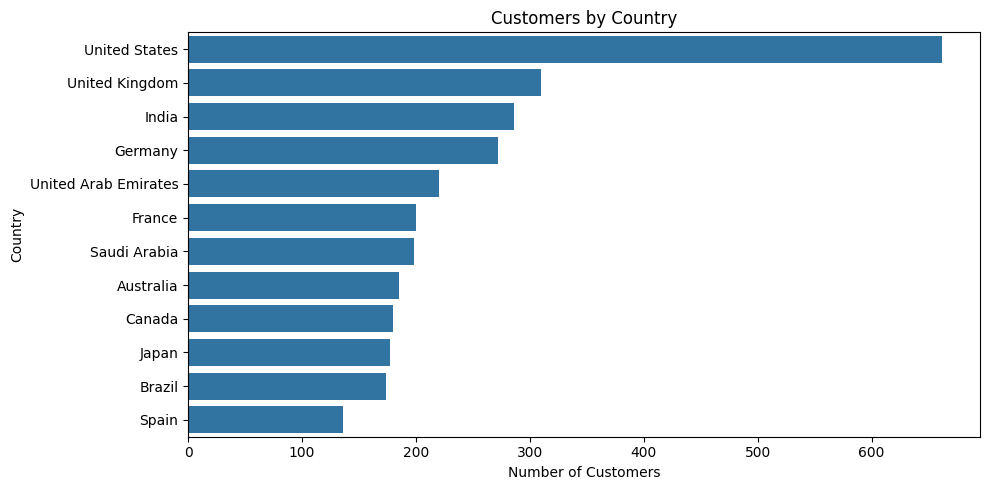

In [66]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=customers,
    y="country",
    order=customers["country"].value_counts().index
)

plt.title("Customers by Country")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Monthly Sales Trend.

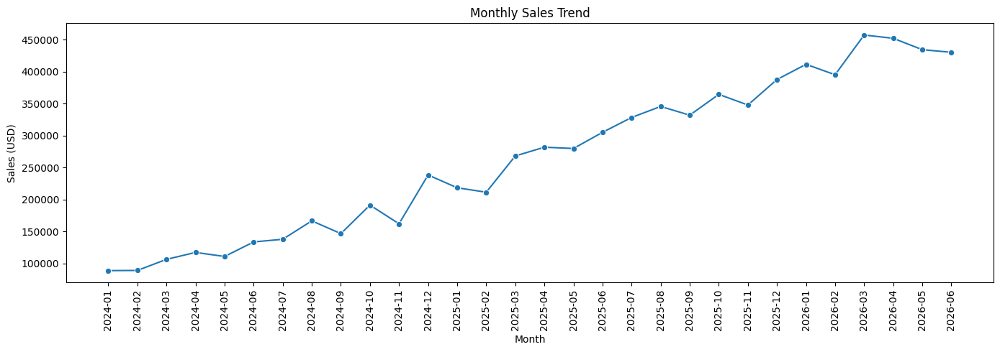

In [67]:
monthly_sales = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["order_total_usd"].sum().reset_index()

monthly_sales["order_date"] = monthly_sales["order_date"].astype(str)

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=monthly_sales,
    x="order_date",
    y="order_total_usd",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (USD)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Distribution of Item Quantities.

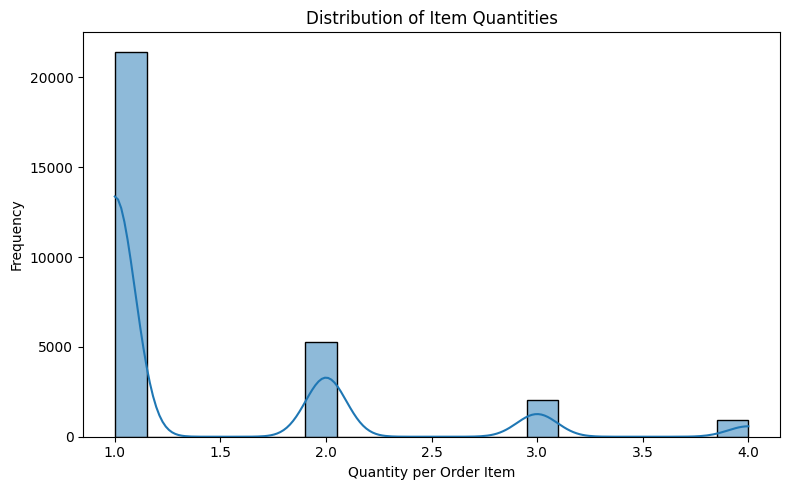

In [68]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=order_items,
    x="quantity",
    bins=20,
    kde=True
)

plt.title("Distribution of Item Quantities")
plt.xlabel("Quantity per Order Item")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Products by Category.

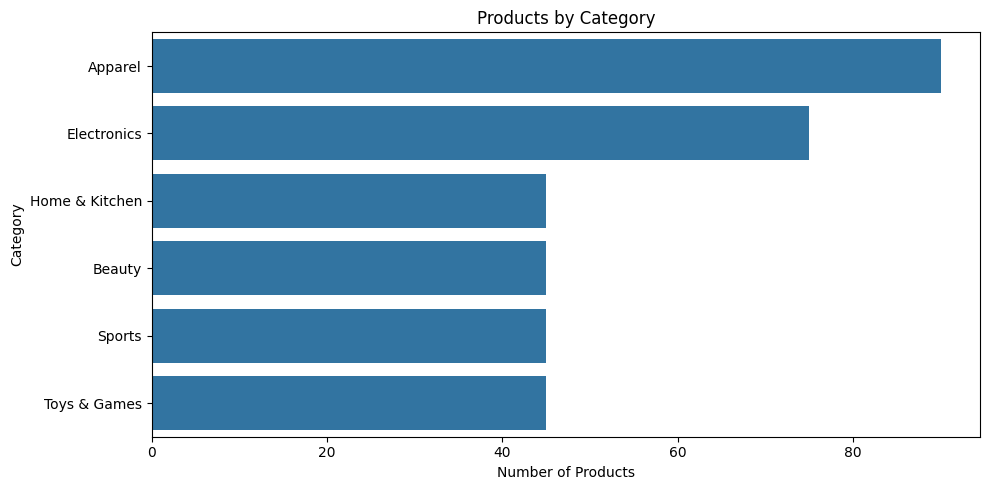

In [69]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=products,
    y="category",
    order=products["category"].value_counts().index
)

plt.title("Products by Category")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Product Returns by Reason.

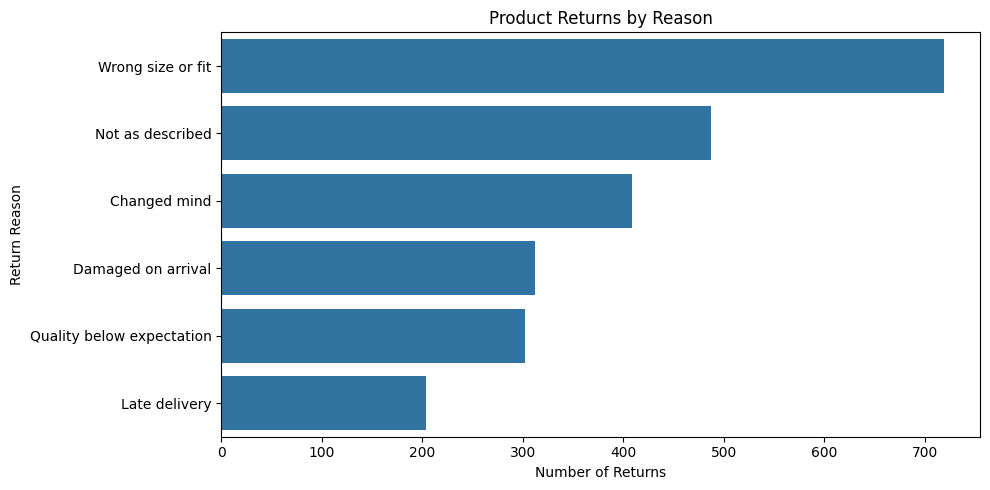

In [70]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=returns,
    y="return_reason",
    order=returns["return_reason"].value_counts().index
)

plt.title("Product Returns by Reason")
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.show()

### Profit by Product Category.

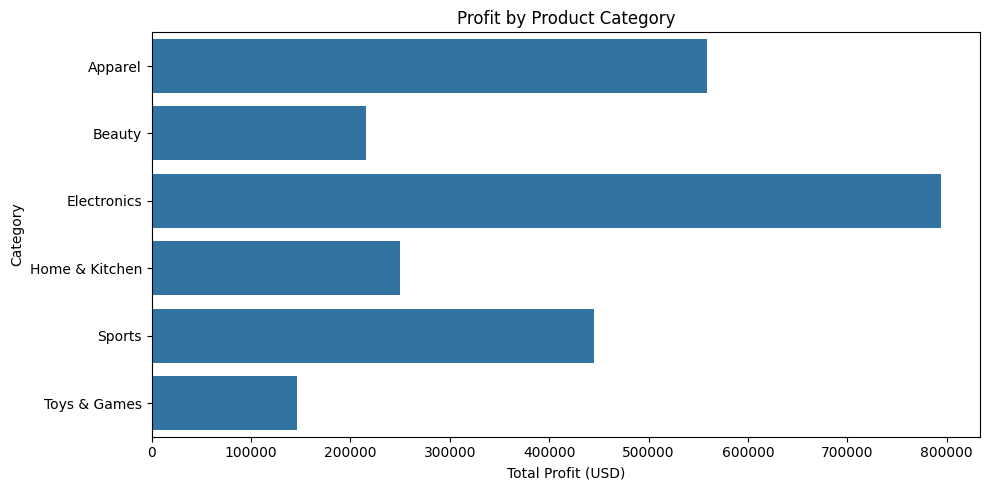

In [71]:
category_profit = order_items.merge(
    products, on="product_id"
).groupby("category")["line_profit_usd"].sum().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_profit,
    x="line_profit_usd",
    y="category"
)

plt.title("Profit by Product Category")
plt.xlabel("Total Profit (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Sales by Channel.

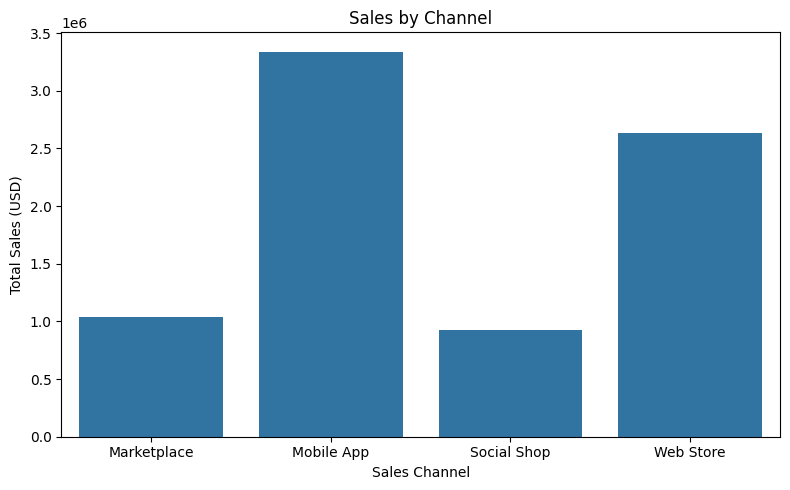

In [72]:
channel_sales = orders.groupby(
    "sales_channel"
)["order_total_usd"].sum().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=channel_sales,
    x="sales_channel",
    y="order_total_usd"
)

plt.title("Sales by Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Sales (USD)")
plt.tight_layout()
plt.show()

### Order Status Distribution.

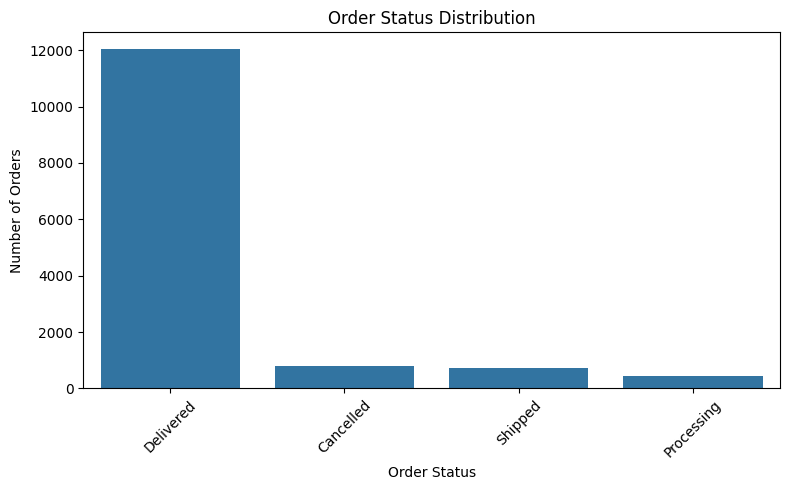

In [73]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Refund Amount by Return Reason.

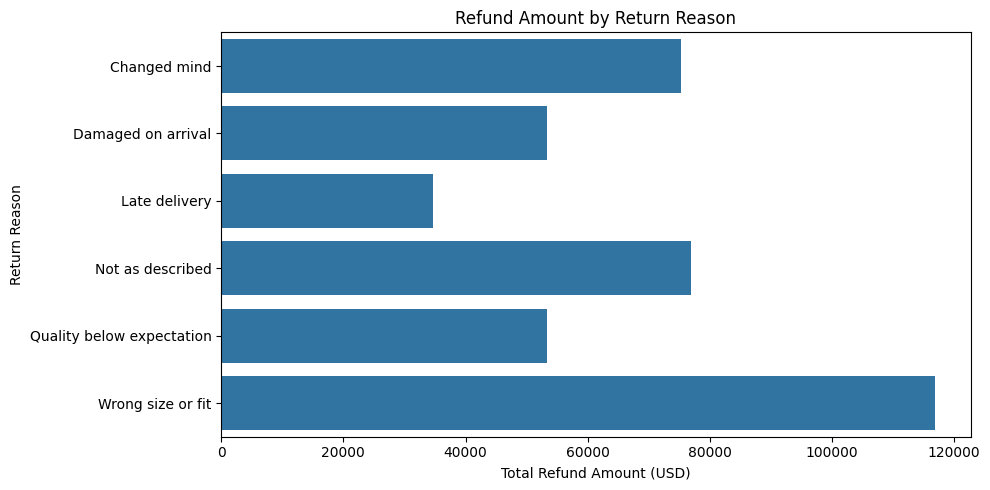

In [74]:
refund_by_reason = returns.groupby(
    "return_reason"
)["refund_amount_usd"].sum().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=refund_by_reason,
    x="refund_amount_usd",
    y="return_reason"
)

plt.title("Refund Amount by Return Reason")
plt.xlabel("Total Refund Amount (USD)")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.show()

## Business Insights

#### Sales performance: Review monthly sales to identify growth patterns and weaker months.

#### Geographic performance: Compare sales across shipping countries to identify the strongest markets.

#### Product performance: Identify the products with the highest quantities sold and the categories generating the most sales.

#### Sales channels: Compare sales across channels to identify the strongest channel.

#### Customer analysis: Identify customers with the highest recorded lifetime spend.

#### Returns: Investigate the most common return reasons and the reasons associated with the highest refund amounts.

#### Profitability: Compare profit across product categories to identify the most profitable categories.